In [1]:
import pandas as pd

df = pd.read_csv("../data/used_car_dataset.csv")

df.head()


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (9582, 11)

Column names:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9582 entries, 0 to 9581
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         9582 non-null   str  
 1   model         9582 non-null   str  
 2   Year          9582 non-null   int64
 3   Age           9582 non-null   int64
 4   kmDriven      9535 non-null   str  
 5   Transmission  9582 non-null   str  
 6   Owner         9582 non-null   str  
 7   FuelType      9582 non-null   str  
 8   PostedDate    9582 non-null   str  
 9   AdditionInfo  9582 non-null   str  
 10  AskPrice      9582 non-null   str  
dtypes: int64(2), str(9)
memory usage: 1.8 MB


In [3]:
print("Sample asking prices:")
print(df["AskPrice"].head(10).to_list())

print("\nSample mileage values:")
print(df["kmDriven"].head(10).to_list())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Sample asking prices:
['₹ 1,95,000', '₹ 3,75,000', '₹ 1,84,999', '₹ 5,65,000', '₹ 6,85,000', '₹ 13,50,000', '₹ 10,25,000', '₹ 59,50,000', '₹ 6,22,000', '₹ 6,49,000']

Sample mileage values:
['98,000 km', '190000.0 km', '77,246 km', '83,500 km', '45,000 km', '83,000 km', '168,000 km', '25,000 km', '33,759 km', '69,713 km']

Missing values in each column:
Brand            0
model            0
Year             0
Age              0
kmDriven        47
Transmission     0
Owner            0
FuelType         0
PostedDate       0
AdditionInfo     0
AskPrice         0
dtype: int64

Duplicate rows: 724


In [4]:
# Make a copy of the original dataset
clean_df = df.copy()

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Convert asking prices into numbers
clean_df["AskPrice"] = (
    clean_df["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

# Convert mileage into numbers
clean_df["kmDriven"] = (
    clean_df["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("km", "", regex=False)
    .str.strip()
)

clean_df["kmDriven"] = pd.to_numeric(
    clean_df["kmDriven"], errors="coerce"
)

# Check the result
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(clean_df))
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCleaned sample:")
display(clean_df[["Brand", "Year", "Age", "kmDriven", "AskPrice"]].head())

Original rows: 9582
Rows after removing duplicates: 8858

Missing values after cleaning:
Brand            0
model            0
Year             0
Age              0
kmDriven        46
Transmission     0
Owner            0
FuelType         0
PostedDate       0
AdditionInfo     0
AskPrice         0
dtype: int64

Cleaned sample:


,Brand,Year,Age,kmDriven,AskPrice
0,Honda,2001,23,98000.0,195000.0
1,Toyota,2009,15,190000.0,375000.0
2,Volkswagen,2010,14,77246.0,184999.0
3,Maruti Suzuki,2017,7,83500.0,565000.0
4,Maruti Suzuki,2019,5,45000.0,685000.0


In [5]:
print("Total cars in cleaned dataset:", len(clean_df))

print("\nAll columns:")
print(clean_df.columns.tolist())

print("\nFirst 10 cars:")
display(clean_df.head(10))

Total cars in cleaned dataset: 8858

All columns:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

First 10 cars:


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0
5,BMW,X3,2014,10,83000.0,Automatic,first,Diesel,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0
6,Toyota,Innova,2014,10,168000.0,Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel",1025000.0
7,BMW,5 Series,2019,5,25000.0,Automatic,second,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0
8,Maruti Suzuki,maruti-suzuki-dzire,2020,4,33759.0,Manual,second,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol",622000.0
9,Ford,Ecosport,2017,7,69713.0,Manual,second,Petrol,Nov-24,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...",649000.0


In [6]:
# Summary statistics for numerical columns
display(clean_df[["Year", "Age", "kmDriven", "AskPrice"]].describe())

# Check whether Age and Year are consistent
print("Year and Age consistency:")
print((clean_df["Year"] + clean_df["Age"]).value_counts().head(10))

# Check the most common car brands
print("\nTop 10 brands:")
print(clean_df["Brand"].value_counts().head(10))

# Check missing mileage records
print("\nRows with missing mileage:")
display(clean_df[clean_df["kmDriven"].isnull()][
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
].head(10))

,Year,Age,kmDriven,AskPrice
count,8858.000000,8858.000000,8812.000000,8.858000e+03
mean,2016.377060,7.622940,71034.031321,1.038403e+06
std,4.134203,4.134203,57032.604806,1.649619e+06
min,1986.000000,0.000000,0.000000,1.500000e+04
25%,2014.000000,5.000000,43000.000000,3.500000e+05
50%,2017.000000,7.000000,65137.500000,5.900000e+05
75%,2019.000000,10.000000,86000.000000,1.075000e+06
max,2024.000000,38.000000,980002.000000,4.250000e+07


Year and Age consistency:
2024    8858
Name: count, dtype: int64

Top 10 brands:
Brand
Maruti Suzuki    2590
Hyundai          1437
Honda             730
Toyota            723
Mahindra          545
Tata              372
Mercedes-Benz     347
Volkswagen        278
BMW               256
Ford              231
Name: count, dtype: int64

Rows with missing mileage:


,Brand,model,Year,Age,kmDriven,AskPrice
231,Maruti Suzuki,Alto-800,2019,5,NaN,300000.0
353,Toyota,Innova,2016,8,NaN,860000.0
444,Honda,City ZX,2024,0,NaN,1550000.0
476,Hyundai,Santro Xing,2010,14,NaN,120000.0
608,Toyota,Etios,2012,12,NaN,330000.0
793,Skoda,Kushaq,2010,14,NaN,400000.0
976,Mahindra,Bolero Neo Plus,2015,9,NaN,450000.0
1164,Mahindra,Bolero Neo,2023,1,NaN,1000000.0
1199,Tata,Indica,2014,10,NaN,250000.0
1413,Hyundai,Santro Xing,2007,17,NaN,148000.0


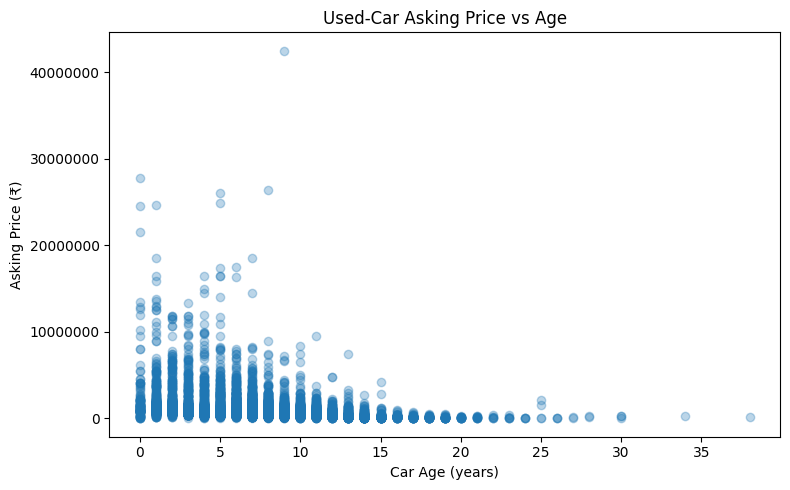

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(clean_df["Age"], clean_df["AskPrice"], alpha=0.3)
plt.xlabel("Car Age (years)")
plt.ylabel("Asking Price (₹)")
plt.title("Used-Car Asking Price vs Age")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [8]:
# Show the 15 cars with the highest asking prices
display(
    clean_df.nlargest(15, "AskPrice")[
        ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
    ]
)

,Brand,model,Year,Age,kmDriven,AskPrice
3331,Rolls-Royce,Phantom Series II,2015,9,11500.0,42500000.0
962,Lexus,LX,2024,0,24000.0,27750000.0
331,Aston Martin,Vanquish,2016,8,25700.0,26400000.0
811,Mercedes-Benz,G Class,2019,5,59000.0,26000000.0
5767,Mercedes-Benz,G Class,2019,5,59000.0,24900000.0
1187,Toyota,Land Cruiser,2023,1,15000.0,24700000.0
7435,Mercedes-Benz,SL-Class,2024,0,1400.0,24500000.0
9241,Mercedes-Benz,AMG,2024,0,16000.0,21500000.0
5621,BMW,7 Series,2023,1,7000.0,18500000.0
7615,Bentley,Flying Spur,2017,7,22000.0,18500000.0


    Age   AskPrice
0     0  1350000.0
1     1  1450000.0
2     2  1150000.0
3     3  1040000.0
4     4   875000.0
5     5   775000.0
6     6   670000.0
7     7   645000.0
8     8   550000.0
9     9   485000.0
10   10   450000.0
11   11   385000.0
12   12   321000.0
13   13   245000.0
14   14   210000.0


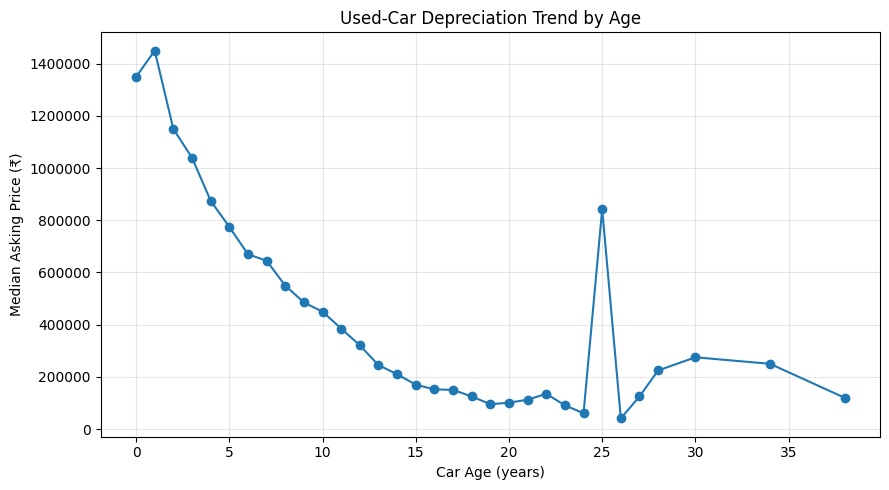

In [9]:
# Calculate median asking price for each car age
age_prices = (
    clean_df.groupby("Age")["AskPrice"]
    .median()
    .reset_index()
)

print(age_prices.head(15))

# Plot the depreciation curve
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    age_prices["Age"],
    age_prices["AskPrice"],
    marker="o"
)

plt.xlabel("Car Age (years)")
plt.ylabel("Median Asking Price (₹)")
plt.title("Used-Car Depreciation Trend by Age")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
age_summary = (
    clean_df.groupby("Age")
    .agg(
        Car_Count=("AskPrice", "size"),
        Median_Price=("AskPrice", "median")
    )
    .reset_index()
)

print(age_summary.to_string(index=False))

 Age  Car_Count  Median_Price
   0        135     1350000.0
   1        329     1450000.0
   2        520     1150000.0
   3        533     1040000.0
   4        530      875000.0
   5        775      775000.0
   6        852      670000.0
   7        956      645000.0
   8        806      550000.0
   9        781      485000.0
  10        594      450000.0
  11        486      385000.0
  12        441      321000.0
  13        389      245000.0
  14        291      210000.0
  15        151      170000.0
  16         84      152000.0
  17         72      150000.0
  18         39      125000.0
  19         32       94999.5
  20         18      101000.0
  21         12      112500.0
  22          6      135000.0
  23          6       91000.0
  24          4       60500.0
  25          4      842500.0
  26          3       41000.0
  27          2      125000.0
  28          2      224500.0
  30          3      275000.0
  34          1      250000.0
  38          1      120000.0


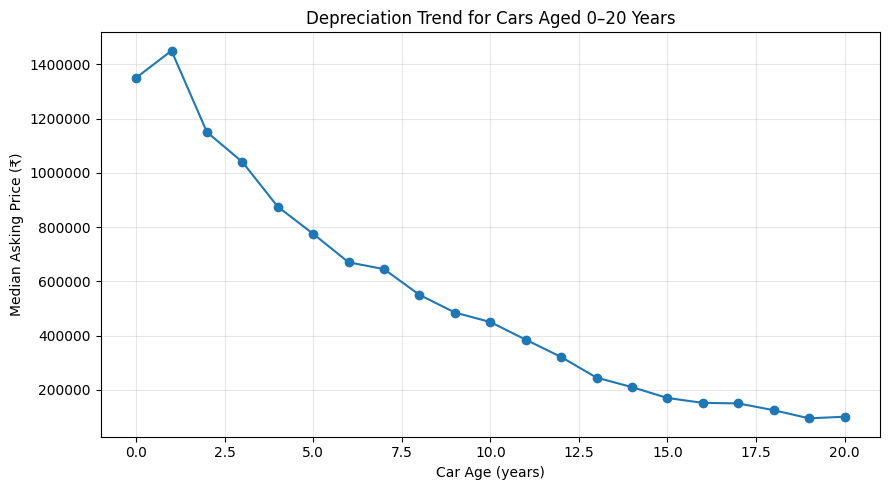

In [11]:
import matplotlib.pyplot as plt

# Keep ages from 0 to 20 for this exploratory curve
curve_data = age_summary[
    (age_summary["Age"] >= 0) &
    (age_summary["Age"] <= 20)
].copy()

plt.figure(figsize=(9, 5))

plt.plot(
    curve_data["Age"],
    curve_data["Median_Price"],
    marker="o"
)

plt.xlabel("Car Age (years)")
plt.ylabel("Median Asking Price (₹)")
plt.title("Depreciation Trend for Cars Aged 0–20 Years")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
curve_data["Yearly_Price_Change_%"] = (
    curve_data["Median_Price"].pct_change() * 100
)

display(
    curve_data[
        ["Age", "Car_Count", "Median_Price", "Yearly_Price_Change_%"]
    ].round(2)
)

,Age,Car_Count,Median_Price,Yearly_Price_Change_%
0,0,135,1350000.0,NaN
1,1,329,1450000.0,7.41
2,2,520,1150000.0,-20.69
3,3,533,1040000.0,-9.57
4,4,530,875000.0,-15.87
5,5,775,775000.0,-11.43
6,6,852,670000.0,-13.55
7,7,956,645000.0,-3.73
8,8,806,550000.0,-14.73
9,9,781,485000.0,-11.82


In [13]:
print("Columns:", df.columns.tolist())
print("\nNumber of unique car models:", df["model"].nunique())
print("\nAge range:", df["Age"].min(), "to", df["Age"].max())
print("\nPrice range:")
print(df["AskPrice"].head(10))

Columns: ['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Number of unique car models: 400

Age range: 0 to 38

Price range:
0     ₹ 1,95,000
1     ₹ 3,75,000
2     ₹ 1,84,999
3     ₹ 5,65,000
4     ₹ 6,85,000
5    ₹ 13,50,000
6    ₹ 10,25,000
7    ₹ 59,50,000
8     ₹ 6,22,000
9     ₹ 6,49,000
Name: AskPrice, dtype: str


In [14]:
# Convert asking price from text to numeric values
df["AskPrice"] = (
    df["AskPrice"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["AskPrice"] = pd.to_numeric(df["AskPrice"], errors="coerce")

# Check the results
print(df["AskPrice"].dtype)
print(df["AskPrice"].describe())
print("Missing prices:", df["AskPrice"].isna().sum())

int64
count    9.582000e+03
mean     1.063609e+06
std      1.658495e+06
min      1.500000e+04
25%      3.610000e+05
50%      5.990000e+05
75%      1.125000e+06
max      4.250000e+07
Name: AskPrice, dtype: float64
Missing prices: 0


In [15]:
# Convert mileage into numeric values
df["kmDriven"] = (
    df["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["kmDriven"] = pd.to_numeric(df["kmDriven"], errors="coerce")

# Check the results
print("Mileage data type:", df["kmDriven"].dtype)
print("Missing mileage values:", df["kmDriven"].isna().sum())
print(df["kmDriven"].describe())

Mileage data type: float64
Missing mileage values: 47
count      9535.000000
mean      70605.891453
std       56308.596299
min           0.000000
25%       43000.000000
50%       65000.000000
75%       86000.000000
max      980002.000000
Name: kmDriven, dtype: float64


In [16]:
# Create a working copy for analysis
df_clean = df.copy()

# Remove rows where mileage is missing
df_clean = df_clean.dropna(subset=["kmDriven"]).copy()

print("Original number of rows:", len(df))
print("Rows after handling missing mileage:", len(df_clean))
print("Remaining missing mileage:", df_clean["kmDriven"].isna().sum())


Original number of rows: 9582
Rows after handling missing mileage: 9535
Remaining missing mileage: 0


In [17]:

print("Manufacturing year range:")
print(df_clean["Year"].min(), "to", df_clean["Year"].max())

print("\nCar age range:")
print(df_clean["Age"].min(), "to", df_clean["Age"].max())

print("\nRows where Year + Age does not equal 2024:")
print((df_clean["Year"] + df_clean["Age"] != 2024).sum())

print("\nSample of Year and Age:")
print(df_clean[["Year", "Age"]].head(10))

Manufacturing year range:
1986 to 2024

Car age range:
0 to 38

Rows where Year + Age does not equal 2024:
0

Sample of Year and Age:
   Year  Age
0  2001   23
1  2009   15
2  2010   14
3  2017    7
4  2019    5
5  2014   10
6  2014   10
7  2019    5
8  2020    4
9  2017    7


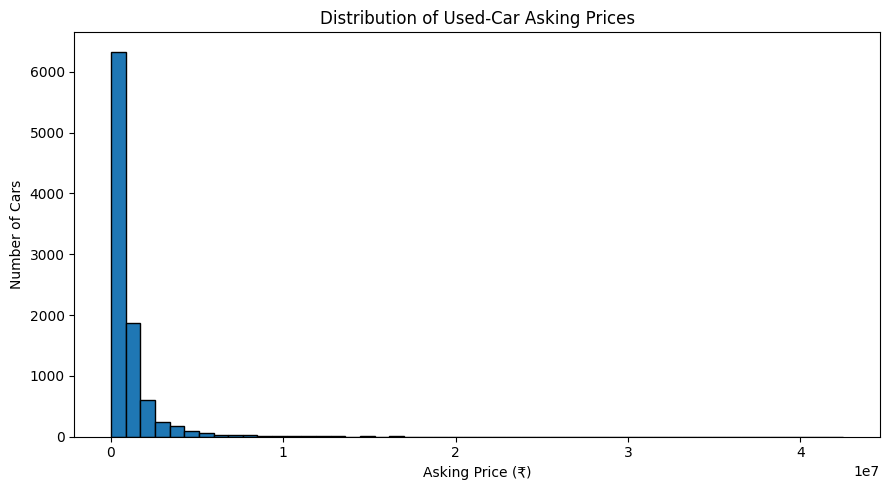

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df_clean["AskPrice"], bins=50, edgecolor="black")
plt.title("Distribution of Used-Car Asking Prices")
plt.xlabel("Asking Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

In [19]:
# Inspect the 15 most expensive listings
expensive_cars = df_clean.nlargest(15, "AskPrice")

display(
    expensive_cars[
        ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
    ]
)

,Brand,model,Year,Age,kmDriven,AskPrice
3331,Rolls-Royce,Phantom Series II,2015,9,11500.0,42500000
962,Lexus,LX,2024,0,24000.0,27750000
331,Aston Martin,Vanquish,2016,8,25700.0,26400000
811,Mercedes-Benz,G Class,2019,5,59000.0,26000000
5767,Mercedes-Benz,G Class,2019,5,59000.0,24900000
1187,Toyota,Land Cruiser,2023,1,15000.0,24700000
7435,Mercedes-Benz,SL-Class,2024,0,1400.0,24500000
9241,Mercedes-Benz,AMG,2024,0,16000.0,21500000
5621,BMW,7 Series,2023,1,7000.0,18500000
7615,Bentley,Flying Spur,2017,7,22000.0,18500000


In [20]:
# Calculate the median asking price for each car age
age_summary = (
    df_clean.groupby("Age")
    .agg(
        Car_Count=("AskPrice", "count"),
        Median_Price=("AskPrice", "median")
    )
    .reset_index()
)

# Display ages with at least 10 listings
age_summary = age_summary[age_summary["Car_Count"] >= 10]

display(age_summary.head(15))

,Age,Car_Count,Median_Price
0,0,148,1350000.0
1,1,334,1462500.0
2,2,542,1160000.0
3,3,563,1050000.0
4,4,559,875000.0
5,5,842,775000.0
6,6,926,675000.0
7,7,1034,645000.0
8,8,893,560000.0
9,9,885,500000.0


In [21]:

# Inspect the cleaned dataset before model development

print("Number of rows and columns:", df_clean.shape)

print("\nAvailable columns:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nFirst 5 rows:")
display(df_clean.head())


Number of rows and columns: (9535, 11)

Available columns:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Data types:
Brand               str
model               str
Year              int64
Age               int64
kmDriven        float64
Transmission        str
Owner               str
FuelType            str
PostedDate          str
AdditionInfo        str
AskPrice          int64
dtype: object

Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
PostedDate      0
AdditionInfo    0
AskPrice        0
dtype: int64

First 5 rows:


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000


In [22]:

# Select the features and target for price prediction

features = [
    "Age",
    "kmDriven",
    "Brand",
    "model",
    "FuelType",
    "Transmission",
    "Owner"
]

target = "AskPrice"

# Create the modelling dataset
model_df = df_clean[features + [target]].copy()

print("Modelling dataset shape:", model_df.shape)
print("\nMissing values:")
print(model_df.isnull().sum())

print("\nFeature columns:")
print(features)

print("\nTarget column:", target)

display(model_df.head())


Modelling dataset shape: (9535, 8)

Missing values:
Age             0
kmDriven        0
Brand           0
model           0
FuelType        0
Transmission    0
Owner           0
AskPrice        0
dtype: int64

Feature columns:
['Age', 'kmDriven', 'Brand', 'model', 'FuelType', 'Transmission', 'Owner']

Target column: AskPrice


,Age,kmDriven,Brand,model,FuelType,Transmission,Owner,AskPrice
0,23,98000.0,Honda,City,Petrol,Manual,second,195000
1,15,190000.0,Toyota,Innova,Diesel,Manual,second,375000
2,14,77246.0,Volkswagen,VentoTest,Diesel,Manual,first,184999
3,7,83500.0,Maruti Suzuki,Swift,Diesel,Manual,second,565000
4,5,45000.0,Maruti Suzuki,Baleno,Petrol,Automatic,first,685000


In [23]:

from sklearn.model_selection import train_test_split

# Separate the input features and target price
X = model_df[features]
y = model_df[target]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Total rows:", len(X))


Training rows: 7628
Testing rows: 1907
Total rows: 9535


In [24]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create and train the baseline model
baseline_model = DummyRegressor(strategy="median")
baseline_model.fit(X_train, y_train)

# Predict prices for the test data
baseline_predictions = baseline_model.predict(X_test)

# Evaluate the predictions
mae = mean_absolute_error(y_test, baseline_predictions)
rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print(f"MAE:  ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


BASELINE MODEL RESULTS
MAE:  ₹680,376.58
RMSE: ₹1,569,101.95
R² Score: -0.0864


In [25]:

print("Missing values in modelling dataset:")
print(model_df.isnull().sum())


Missing values in modelling dataset:
Age             0
kmDriven        0
Brand           0
model           0
FuelType        0
Transmission    0
Owner           0
AskPrice        0
dtype: int64


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Separate numerical and categorical features
numeric_features = ["Age", "kmDriven"]
categorical_features = [
    "Brand", "model", "FuelType", "Transmission", "Owner"
]

# Convert text categories into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Create the regression pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train using training data only
linear_model.fit(X_train, y_train)

# Predict prices for unseen test data
linear_predictions = linear_model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, linear_predictions)
rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
r2 = r2_score(y_test, linear_predictions)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print(f"MAE:  ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


MULTIPLE LINEAR REGRESSION RESULTS
MAE:  ₹607,973.61
RMSE: ₹1,196,042.35
R² Score: 0.3688


In [27]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict prices for the test dataset
rf_predictions = random_forest_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST REGRESSION RESULTS")
print(f"MAE:  ₹{rf_mae:,.2f}")
print(f"RMSE: ₹{rf_rmse:,.2f}")
print(f"R² Score: {rf_r2:.4f}")


RANDOM FOREST REGRESSION RESULTS
MAE:  ₹236,167.22
RMSE: ₹805,310.76
R² Score: 0.7138


In [28]:

import joblib

joblib.dump(random_forest_model, "../random_forest_model.pkl")

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


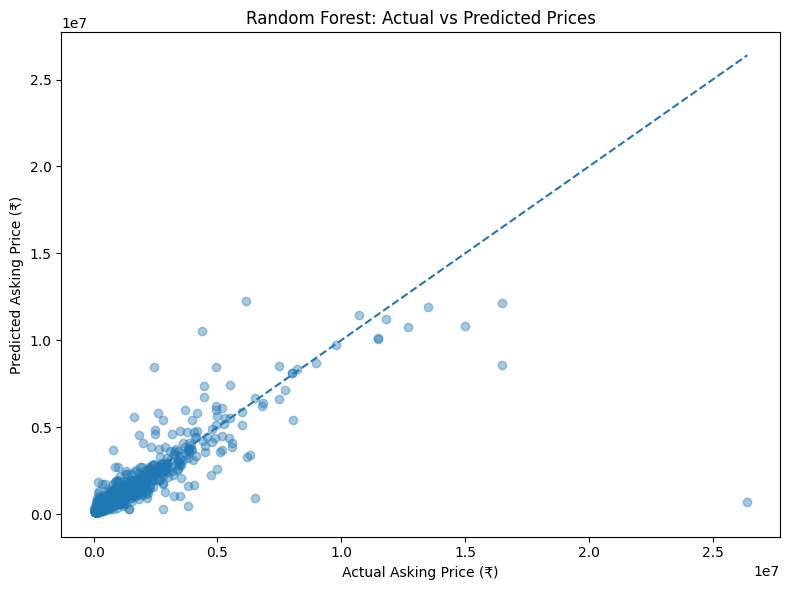

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

# Ideal prediction line
min_price = min(y_test.min(), rf_predictions.min())
max_price = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Asking Price (₹)")
plt.ylabel("Predicted Asking Price (₹)")
plt.title("Random Forest: Actual vs Predicted Prices")
plt.tight_layout()
plt.show()


In [30]:

import pandas as pd
import numpy as np

# Compare actual and predicted prices
error_analysis = X_test.copy()

error_analysis["Actual_Price"] = y_test
error_analysis["Predicted_Price"] = rf_predictions

error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Actual_Price"]
    - error_analysis["Predicted_Price"]
)

error_analysis["Error_Percentage"] = (
    error_analysis["Absolute_Error"]
    / error_analysis["Actual_Price"].replace(0, np.nan)
) * 100

# Show the 15 largest prediction errors
worst_predictions = error_analysis.sort_values(
    "Absolute_Error", ascending=False
)

print("15 CARS WITH THE LARGEST PREDICTION ERRORS")

display(
    worst_predictions[
        [
            "Brand", "model", "Age", "kmDriven",
            "Actual_Price", "Predicted_Price",
            "Absolute_Error", "Error_Percentage"
        ]
    ].head(15).round(2)
)


15 CARS WITH THE LARGEST PREDICTION ERRORS


,Brand,model,Age,kmDriven,Actual_Price,Predicted_Price,Absolute_Error,Error_Percentage
331,Aston Martin,Vanquish,8,25700.0,26400000,717310.50,25682689.50,97.28
7074,Toyota,Land Cruiser,5,40000.0,16500000,8577679.64,7922320.36,48.01
8179,Land Rover,Discovery,5,28000.0,4375000,10556592.93,6181592.93,141.29
2194,Mercedes-Benz,E-Class,0,8000.0,6175000,12280400.00,6105400.00,98.87
2626,Mercedes-Benz,GLA,5,51000.0,2440000,8445202.90,6005202.90,246.11
1231,Tata,Punch,2,7200.0,6500000,921234.53,5578765.47,85.83
4096,Land Rover,Range Rover,4,48000.0,16500000,12116442.16,4383557.84,26.57
8478,Porsche,Panamera,4,20000.0,15000000,10818796.83,4181203.17,27.87
2983,Mercedes-Benz,CLA,7,36250.0,1650000,5582140.67,3932140.67,238.31
1972,Mercedes-Benz,GLA,2,20500.0,4950000,8464548.02,3514548.02,71.00


In [31]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train using log-transformed prices
log_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

log_rf_model.fit(X_train, np.log1p(y_train))

# Convert predictions back into rupees
log_rf_predictions = np.expm1(log_rf_model.predict(X_test))

# Evaluate in the original price scale
log_mae = mean_absolute_error(y_test, log_rf_predictions)
log_rmse = np.sqrt(mean_squared_error(y_test, log_rf_predictions))
log_r2 = r2_score(y_test, log_rf_predictions)

print("RANDOM FOREST WITH LOG-TRANSFORMED TARGET")
print(f"MAE:  ₹{log_mae:,.2f}")
print(f"RMSE: ₹{log_rmse:,.2f}")
print(f"R² Score: {log_r2:.4f}")


RANDOM FOREST WITH LOG-TRANSFORMED TARGET
MAE:  ₹231,852.49
RMSE: ₹829,023.81
R² Score: 0.6967


In [32]:
import joblib

joblib.dump(random_forest_model, "../random_forest_model.pkl")

print("Final original Random Forest model saved successfully!")

Final original Random Forest model saved successfully!


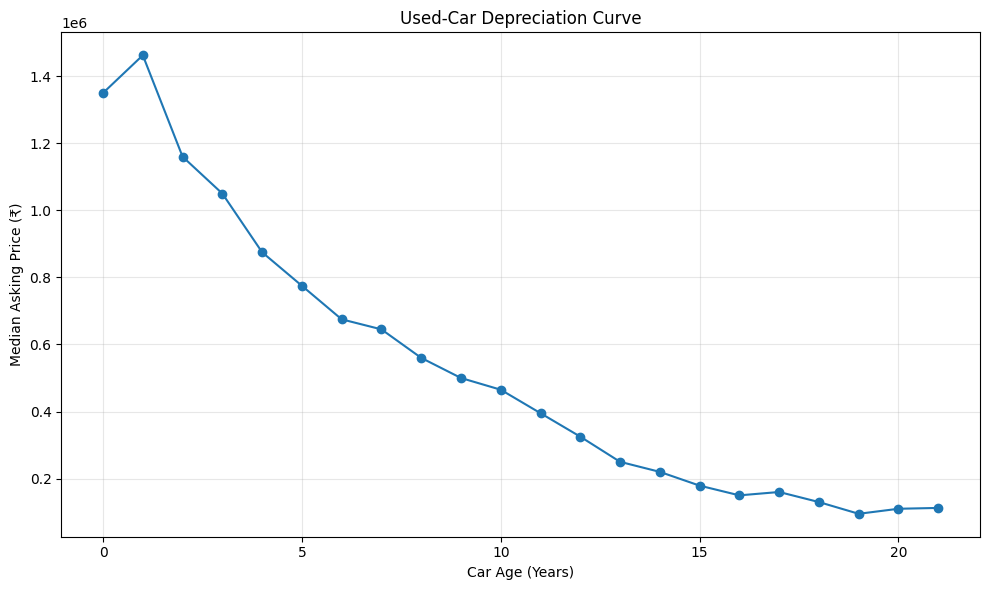

In [35]:

import matplotlib.pyplot as plt

# Keep age groups with at least 10 listings
depreciation_data = age_summary[
    age_summary["Car_Count"] >= 10
].sort_values("Age").copy()

plt.figure(figsize=(10, 6))

plt.plot(
    depreciation_data["Age"],
    depreciation_data["Median_Price"],
    marker="o"
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Median Asking Price (₹)")
plt.title("Used-Car Depreciation Curve")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
plt.savefig("../depreciation_curve.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [37]:
print("Original dataset rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows in modelling dataset:", len(model_df))

Original dataset rows: 9582
Exact duplicate rows: 731
Rows in modelling dataset: 9535


In [38]:
print("Duplicate rows in modelling dataset:", model_df.duplicated().sum())

Duplicate rows in modelling dataset: 820


In [39]:

# Create a separate modelling dataset without exact duplicate rows
model_df_clean = model_df.drop_duplicates().copy()

print("Rows before removing duplicates:", len(model_df))
print("Rows after removing duplicates:", len(model_df_clean))
print("Duplicates remaining:", model_df_clean.duplicated().sum())


Rows before removing duplicates: 9535
Rows after removing duplicates: 8715
Duplicates remaining: 0


In [40]:

from sklearn.model_selection import train_test_split

# Separate features and target
X_clean = model_df_clean[features]
y_clean = model_df_clean["AskPrice"]

# Split into training and testing sets
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42
)

print("Total rows:", len(X_clean))
print("Training rows:", len(X_train_clean))
print("Testing rows:", len(X_test_clean))


Total rows: 8715
Training rows: 6972
Testing rows: 1743


In [41]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest pipeline
final_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the cleaned training data
final_rf_model.fit(X_train_clean, y_train_clean)

# Predict prices on the cleaned test data
final_rf_predictions = final_rf_model.predict(X_test_clean)

# Evaluate the final model
final_mae = mean_absolute_error(y_test_clean, final_rf_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test_clean, final_rf_predictions))
final_r2 = r2_score(y_test_clean, final_rf_predictions)

print("FINAL RANDOM FOREST RESULTS (CLEANED DATA)")
print(f"MAE:  ₹{final_mae:,.2f}")
print(f"RMSE: ₹{final_rmse:,.2f}")
print(f"R² Score: {final_r2:.4f}")


FINAL RANDOM FOREST RESULTS (CLEANED DATA)
MAE:  ₹277,458.40
RMSE: ₹931,662.50
R² Score: 0.6896


In [42]:

import joblib

joblib.dump(final_rf_model, "../random_forest_model.pkl")

print("Final model saved successfully!")


Final model saved successfully!


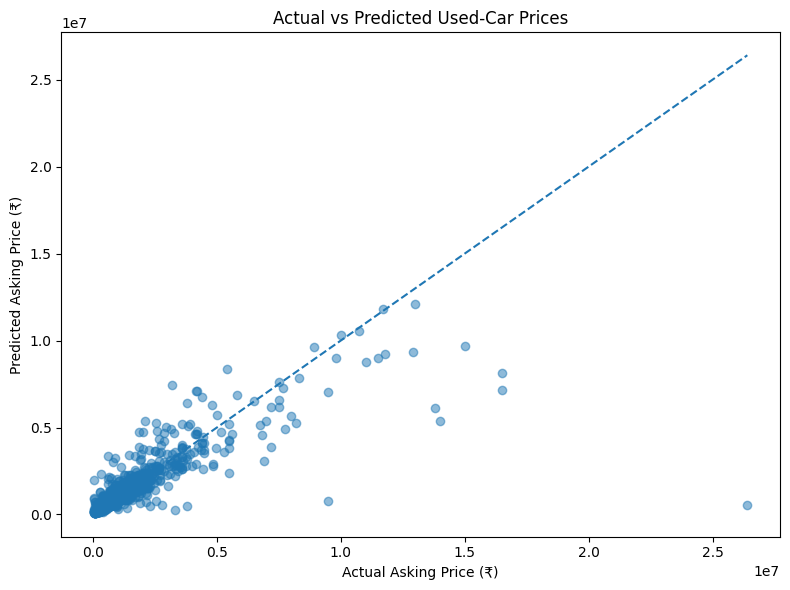

In [43]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_clean,
    final_rf_predictions,
    alpha=0.5
)

plt.plot(
    [y_test_clean.min(), y_test_clean.max()],
    [y_test_clean.min(), y_test_clean.max()],
    linestyle="--"
)

plt.xlabel("Actual Asking Price (₹)")
plt.ylabel("Predicted Asking Price (₹)")
plt.title("Actual vs Predicted Used-Car Prices")
plt.tight_layout()

plt.savefig("../actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


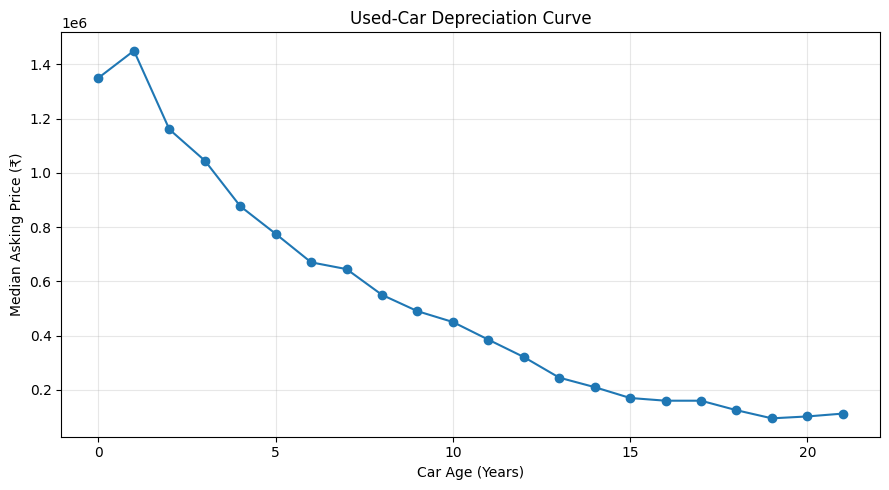

In [44]:

# Group cars by age and calculate their median asking price
age_summary = (
    model_df_clean.groupby("Age")
    .agg(
        Car_Count=("AskPrice", "count"),
        Median_Price=("AskPrice", "median")
    )
    .reset_index()
)

# Keep age groups with at least 10 cars
age_summary = age_summary[age_summary["Car_Count"] >= 10]

# Plot the depreciation curve
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    age_summary["Age"],
    age_summary["Median_Price"],
    marker="o"
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Median Asking Price (₹)")
plt.title("Used-Car Depreciation Curve")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("../depreciation_curve.png", dpi=300, bbox_inches="tight")
plt.show()


In [45]:

sample_car = {
    "Age": 5,
    "kmDriven": 50000,
    "Brand": "Maruti",
    "model": "Swift",
    "FuelType": "Petrol",
    "Transmission": "Manual",
    "Owner": "First Owner"
}

sample_car_df = pd.DataFrame([sample_car])

predicted_price = final_rf_model.predict(sample_car_df)[0]

print(f"Predicted used-car price: ₹{predicted_price:,.0f}")


Predicted used-car price: ₹547,743


In [46]:

error_check = pd.DataFrame({
    "Actual_Price": y_test_clean,
    "Predicted_Price": final_rf_predictions
})

error_check["Absolute_Error"] = abs(
    error_check["Actual_Price"] - error_check["Predicted_Price"]
)

error_check = error_check.sort_values(
    "Absolute_Error", ascending=False
)

error_check.head(10)


,Actual_Price,Predicted_Price,Absolute_Error
331,26400000,5.380957e+05,2.586190e+07
9437,16500000,7.165666e+06,9.334334e+06
6611,9500000,7.802688e+05,8.719731e+06
7178,14000000,5.369766e+06,8.630234e+06
7074,16500000,8.158082e+06,8.341918e+06
6069,13800000,6.141361e+06,7.658639e+06
8478,15000000,9.707914e+06,5.292086e+06
6453,3195000,7.430701e+06,4.235701e+06
7643,6900000,3.069462e+06,3.830538e+06
9394,12900000,9.321675e+06,3.578325e+06


In [47]:

# Get the original car details for the 10 largest errors
error_details = X_test_clean.loc[error_check.head(10).index].copy()

error_details["Actual_Price"] = y_test_clean.loc[error_details.index]
error_details["Predicted_Price"] = final_rf_predictions[
    error_check.index.get_indexer(error_details.index)
]

error_details["Absolute_Error"] = abs(
    error_details["Actual_Price"] - error_details["Predicted_Price"]
)

error_details.sort_values(
    "Absolute_Error", ascending=False
)


,Age,kmDriven,Brand,model,FuelType,Transmission,Owner,Actual_Price,Predicted_Price,Absolute_Error
331,8,25700.0,Aston Martin,Vanquish,Petrol,Automatic,first,26400000,5.932614e+05,2.580674e+07
9437,5,55000.0,Land Rover,Range Rover,Petrol,Automatic,first,16500000,4.827054e+05,1.601729e+07
8478,4,20000.0,Porsche,Panamera,Petrol,Automatic,first,15000000,2.906668e+05,1.470933e+07
7074,5,40000.0,Toyota,Land Cruiser,Diesel,Automatic,first,16500000,2.244335e+06,1.425566e+07
7178,5,110000.0,Land Rover,Range Rover,Diesel,Automatic,second,14000000,2.789471e+05,1.372105e+07
6069,1,22000.0,Mercedes-Benz,S-Class,Diesel,Automatic,first,13800000,5.040474e+05,1.329595e+07
9394,0,500.0,Toyota,VELLFIRE,Hybrid/CNG,Automatic,first,12900000,5.900817e+05,1.230992e+07
6611,11,250000.0,Toyota,Innova,Diesel,Manual,second,9500000,6.566052e+05,8.843395e+06
7643,5,40000.0,Volvo,XC 90,Diesel,Automatic,first,6900000,4.337566e+05,6.466243e+06
6453,4,51000.0,Mercedes-Benz,C-Class,Petrol,Automatic,first,3195000,3.122870e+05,2.882713e+06


In [48]:
print(df.columns.tolist())

['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']


In [49]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (9582, 11)
Columns: ['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']


In [50]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

NameError: name 'y_pred' is not defined

In [51]:
%whos


Variable                Type                 Data/Info
------------------------------------------------------
ColumnTransformer       ABCMeta              <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DummyRegressor          type                 <class 'sklearn.dummy.DummyRegressor'>
LinearRegression        ABCMeta              <class 'sklearn.linear_mo<...>._base.LinearRegression'>
OneHotEncoder           type                 <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                ABCMeta              <class 'sklearn.pipeline.Pipeline'>
RandomForestRegressor   ABCMeta              <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                       DataFrame            Shape: (9535, 7)
X_clean                 DataFrame            Shape: (8715, 7)
X_test                  DataFrame            Shape: (1907, 7)
X_test_clean            DataFrame            Shape: (1743, 7)
X_train                 DataFrame            Shape: (7628, 7)
X_train_cle

In [52]:
[name for name in globals()
 if "model" in name.lower() or "rf" in name.lower()]

['model_df',
 'baseline_model',
 'linear_model',
 'random_forest_model',
 'rf_predictions',
 'rf_mae',
 'rf_rmse',
 'rf_r2',
 'log_rf_model',
 'log_rf_predictions',
 'model_df_clean',
 'final_rf_model',
 'final_rf_predictions']

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Final Random Forest Model Evaluation")
print("------------------------------------")
print("MAE:", mean_absolute_error(y_test_clean, final_rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test_clean, final_rf_predictions)))
print("R2 Score:", r2_score(y_test_clean, final_rf_predictions))

Final Random Forest Model Evaluation
------------------------------------
MAE: 277458.39811648044
RMSE: 931662.5047982554
R2 Score: 0.689627061592146


In [54]:
error_analysis_clean = X_test_clean.copy()

error_analysis_clean["Actual_Price"] = y_test_clean
error_analysis_clean["Predicted_Price"] = final_rf_predictions

error_analysis_clean["Absolute_Error"] = abs(
    error_analysis_clean["Actual_Price"]
    - error_analysis_clean["Predicted_Price"]
)

error_analysis_clean = error_analysis_clean.sort_values(
    by="Absolute_Error",
    ascending=False
)

error_analysis_clean.head(10)

,Age,kmDriven,Brand,model,FuelType,Transmission,Owner,Actual_Price,Predicted_Price,Absolute_Error
331,8,25700.0,Aston Martin,Vanquish,Petrol,Automatic,first,26400000,5.380957e+05,2.586190e+07
9437,5,55000.0,Land Rover,Range Rover,Petrol,Automatic,first,16500000,7.165666e+06,9.334334e+06
6611,11,250000.0,Toyota,Innova,Diesel,Manual,second,9500000,7.802688e+05,8.719731e+06
7178,5,110000.0,Land Rover,Range Rover,Diesel,Automatic,second,14000000,5.369766e+06,8.630234e+06
7074,5,40000.0,Toyota,Land Cruiser,Diesel,Automatic,first,16500000,8.158082e+06,8.341918e+06
6069,1,22000.0,Mercedes-Benz,S-Class,Diesel,Automatic,first,13800000,6.141361e+06,7.658639e+06
8478,4,20000.0,Porsche,Panamera,Petrol,Automatic,first,15000000,9.707914e+06,5.292086e+06
6453,4,51000.0,Mercedes-Benz,C-Class,Petrol,Automatic,first,3195000,7.430701e+06,4.235701e+06
7643,5,40000.0,Volvo,XC 90,Diesel,Automatic,first,6900000,3.069462e+06,3.830538e+06
9394,0,500.0,Toyota,VELLFIRE,Hybrid/CNG,Automatic,first,12900000,9.321675e+06,3.578325e+06


In [55]:
df_clean[
    (df_clean["Brand"].isin([
        "Aston Martin",
        "Land Rover",
        "Toyota",
        "Mercedes-Benz",
        "Porsche"
    ]))
    & (df_clean["AskPrice"].astype(str).str.replace(
        r"[₹,\s]", "", regex=True
    ).pipe(pd.to_numeric, errors="coerce") > 5_000_000)
][[
    "Brand", "model", "Year", "Age",
    "kmDriven", "FuelType", "Transmission", "AskPrice"
]].sort_values("AskPrice", ascending=False).head(20)

,Brand,model,Year,Age,kmDriven,FuelType,Transmission,AskPrice
331,Aston Martin,Vanquish,2016,8,25700.0,Petrol,Automatic,26400000
811,Mercedes-Benz,G Class,2019,5,59000.0,Petrol,Automatic,26000000
5767,Mercedes-Benz,G Class,2019,5,59000.0,Petrol,Automatic,24900000
1187,Toyota,Land Cruiser,2023,1,15000.0,Diesel,Automatic,24700000
7435,Mercedes-Benz,SL-Class,2024,0,1400.0,Petrol,Automatic,24500000
9241,Mercedes-Benz,AMG,2024,0,16000.0,Petrol,Automatic,21500000
9495,Land Rover,Range Rover,2019,5,29700.0,Diesel,Automatic,17400000
7074,Toyota,Land Cruiser,2019,5,40000.0,Diesel,Automatic,16500000
4096,Land Rover,Range Rover,2020,4,48000.0,Petrol,Automatic,16500000
2152,Land Rover,Range Rover Sport,2023,1,18650.0,Diesel,Automatic,16500000


In [56]:
luxury_cars = df_clean[
    df_clean["AskPrice"].astype(str)
    .str.replace(r"[₹,\s]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce") > 5_000_000
].copy()

luxury_columns = [
    "Brand", "model", "Year", "Age",
    "kmDriven", "FuelType", "Transmission",
    "Owner", "AskPrice"
]

print("High-value listings:", len(luxury_cars))
print(
    "Exact duplicates across selected columns:",
    luxury_cars.duplicated(subset=luxury_columns).sum()
)

luxury_cars[
    luxury_cars.duplicated(
        subset=luxury_columns,
        keep=False
    )
][luxury_columns].sort_values(
    ["Brand", "model", "AskPrice"]
)

High-value listings: 232
Exact duplicates across selected columns: 31


,Brand,model,Year,Age,kmDriven,FuelType,Transmission,Owner,AskPrice
7,BMW,5 Series,2019,5,25000.0,Diesel,Automatic,second,5950000
2714,BMW,5 Series,2019,5,25000.0,Diesel,Automatic,second,5950000
6914,BMW,5 Series,2019,5,25000.0,Diesel,Automatic,second,5950000
949,BMW,X4,2022,2,9000.0,Petrol,Automatic,second,7200000
5710,BMW,X4,2022,2,9000.0,Petrol,Automatic,second,7200000
8012,BMW,X5,2020,4,60000.0,Diesel,Automatic,first,6891000
8101,BMW,X5,2020,4,60000.0,Diesel,Automatic,first,6891000
8465,BMW,X5,2020,4,60000.0,Diesel,Automatic,first,6891000
2417,BMW,X7,2020,4,25700.0,Petrol,Automatic,second,10900000
8222,BMW,X7,2020,4,25700.0,Petrol,Automatic,second,10900000


In [57]:
error_analysis_clean = X_test_clean.copy()

error_analysis_clean["Actual_Price"] = y_test_clean
error_analysis_clean["Predicted_Price"] = final_rf_predictions

error_analysis_clean["Absolute_Error"] = abs(
    error_analysis_clean["Actual_Price"]
    - error_analysis_clean["Predicted_Price"]
)

error_analysis_clean = error_analysis_clean.sort_values(
    by="Absolute_Error",
    ascending=False
)

error_analysis_clean.head(10)

,Age,kmDriven,Brand,model,FuelType,Transmission,Owner,Actual_Price,Predicted_Price,Absolute_Error
331,8,25700.0,Aston Martin,Vanquish,Petrol,Automatic,first,26400000,5.380957e+05,2.586190e+07
9437,5,55000.0,Land Rover,Range Rover,Petrol,Automatic,first,16500000,7.165666e+06,9.334334e+06
6611,11,250000.0,Toyota,Innova,Diesel,Manual,second,9500000,7.802688e+05,8.719731e+06
7178,5,110000.0,Land Rover,Range Rover,Diesel,Automatic,second,14000000,5.369766e+06,8.630234e+06
7074,5,40000.0,Toyota,Land Cruiser,Diesel,Automatic,first,16500000,8.158082e+06,8.341918e+06
6069,1,22000.0,Mercedes-Benz,S-Class,Diesel,Automatic,first,13800000,6.141361e+06,7.658639e+06
8478,4,20000.0,Porsche,Panamera,Petrol,Automatic,first,15000000,9.707914e+06,5.292086e+06
6453,4,51000.0,Mercedes-Benz,C-Class,Petrol,Automatic,first,3195000,7.430701e+06,4.235701e+06
7643,5,40000.0,Volvo,XC 90,Diesel,Automatic,first,6900000,3.069462e+06,3.830538e+06
9394,0,500.0,Toyota,VELLFIRE,Hybrid/CNG,Automatic,first,12900000,9.321675e+06,3.578325e+06


In [58]:
print("Rows before duplicate removal:", len(model_df))
print("Rows after duplicate removal:", len(model_df_clean))
print("Duplicate rows removed:", len(model_df) - len(model_df_clean))

print(
    "Percentage removed:",
    round(
        (len(model_df) - len(model_df_clean)) / len(model_df) * 100,
        2
    ),
    "%"
)

Rows before duplicate removal: 9535
Rows after duplicate removal: 8715
Duplicate rows removed: 820
Percentage removed: 8.6 %


In [59]:
error_analysis["Price_Range"] = pd.cut(
    error_analysis["Actual_Price"],
    bins=[0, 500000, 1000000, 3000000, 5000000, float("inf")],
    labels=[
        "Below ₹5 lakh",
        "₹5–10 lakh",
        "₹10–30 lakh",
        "₹30–50 lakh",
        "Above ₹50 lakh"
    ]
)

price_range_errors = error_analysis.groupby(
    "Price_Range", observed=False
).agg(
    Number_of_Cars=("Actual_Price", "count"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Median_Actual_Price=("Actual_Price", "median")
).round(2)

price_range_errors

,Number_of_Cars,Mean_Absolute_Error,Median_Actual_Price
Price_Range,,,
Below ₹5 lakh,773,94490.97,325000.0
₹5–10 lakh,595,145702.09,685000.0
₹10–30 lakh,431,321043.86,1550000.0
₹30–50 lakh,69,949728.41,3800000.0
Above ₹50 lakh,39,2223986.24,6850000.0


In [60]:
error_analysis["Absolute_Percentage_Error"] = (
    error_analysis["Absolute_Error"]
    / error_analysis["Actual_Price"].abs().clip(lower=1)
) * 100

percentage_errors = error_analysis.groupby(
    "Price_Range", observed=False
).agg(
    Number_of_Cars=("Actual_Price", "count"),
    Mean_Percentage_Error=("Absolute_Percentage_Error", "mean")
).round(2)

percentage_errors

,Number_of_Cars,Mean_Percentage_Error
Price_Range,,
Below ₹5 lakh,773,41.78
₹5–10 lakh,595,19.97
₹10–30 lakh,431,18.74
₹30–50 lakh,69,23.92
Above ₹50 lakh,39,22.05


In [61]:
depreciation_data = (
    model_df_clean.groupby("Age")
    .agg(
        Number_of_Cars=("AskPrice", "count"),
        Median_Price=("AskPrice", "median")
    )
    .reset_index()
    .sort_values("Age")
)

depreciation_data

,Age,Number_of_Cars,Median_Price
0,0,132,1350000.0
1,1,326,1450000.0
2,2,509,1160000.0
3,3,526,1045000.0
4,4,526,876895.0
5,5,765,775000.0
6,6,845,670000.0
7,7,940,645000.0
8,8,796,550000.0
9,9,763,490000.0


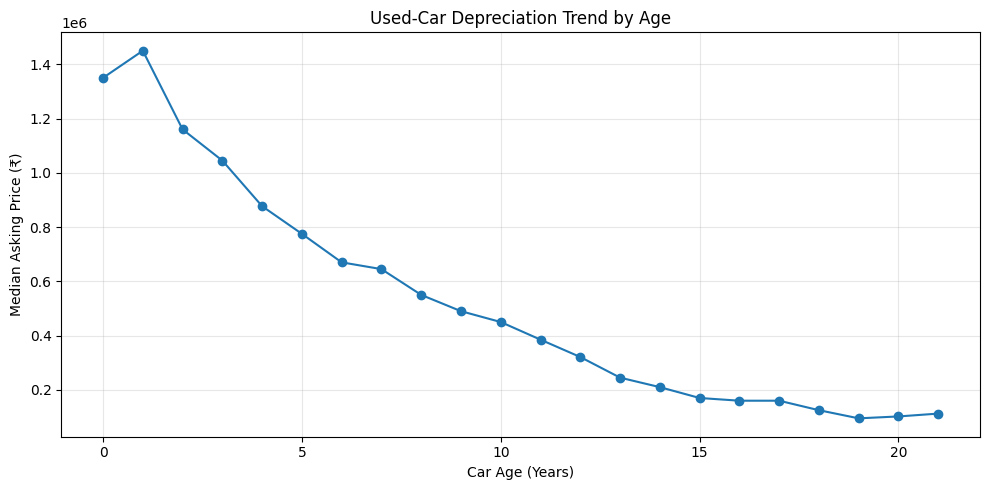

In [62]:
import matplotlib.pyplot as plt

curve_data = depreciation_data[
    depreciation_data["Number_of_Cars"] >= 10
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    curve_data["Age"],
    curve_data["Median_Price"],
    marker="o"
)

plt.title("Used-Car Depreciation Trend by Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Median Asking Price (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("../depreciation_curve.png", dpi=300)
plt.show()

In [63]:
price_age_1 = depreciation_data.loc[
    depreciation_data["Age"] == 1, "Median_Price"
].iloc[0]

price_age_10 = depreciation_data.loc[
    depreciation_data["Age"] == 10, "Median_Price"
].iloc[0]

decline = price_age_1 - price_age_10
decline_percentage = (decline / price_age_1) * 100

print(f"Median price at age 1: ₹{price_age_1:,.0f}")
print(f"Median price at age 10: ₹{price_age_10:,.0f}")
print(f"Price decline: ₹{decline:,.0f}")
print(f"Percentage decline: {decline_percentage:.2f}%")

Median price at age 1: ₹1,450,000
Median price at age 10: ₹450,000
Price decline: ₹1,000,000
Percentage decline: 68.97%


In [64]:
import joblib
import pandas as pd

# Load your saved model
loaded_model = joblib.load("../random_forest_model.pkl")

# Create one new car example
new_car = pd.DataFrame([{
    "Age": 3,
    "kmDriven": 35000,
    "Brand": "Hyundai",
    "model": "Creta",
    "FuelType": "Petrol",
    "Transmission": "Manual",
    "Owner": "first"
}])

# Predict its asking price
predicted_price = loaded_model.predict(new_car)[0]

print(f"Predicted resale price: ₹{predicted_price:,.0f}")

Predicted resale price: ₹1,169,848


In [65]:
test_car_2 = pd.DataFrame([{
    "Age": 8,
    "kmDriven": 90000,
    "Brand": "Hyundai",
    "model": "Creta",
    "FuelType": "Diesel",
    "Transmission": "Manual",
    "Owner": "second"
}])

prediction_2 = loaded_model.predict(test_car_2)[0]

print(f"3-year-old Creta prediction: ₹{predicted_price:,.0f}")
print(f"8-year-old Creta prediction: ₹{prediction_2:,.0f}")
print(f"Difference: ₹{predicted_price - prediction_2:,.0f}")

3-year-old Creta prediction: ₹1,169,848
8-year-old Creta prediction: ₹769,334
Difference: ₹400,514


In [66]:
import os

required_files = [
    "../random_forest_model.pkl",
    "../actual_vs_predicted.png",
    "../depreciation_curve.png"
]

for file in required_files:
    print(
        f"{file}:",
        "Found" if os.path.exists(file) else "Missing"
    )

../random_forest_model.pkl: Found
../actual_vs_predicted.png: Found
../depreciation_curve.png: Found
